In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [2]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep
from threadpoolctl import threadpool_limits

## -- Machine Learning --
if torch.cuda.is_available():
    import cupy as cp
    from cuml.neighbors import KNeighborsClassifier
    from cuml.linear_model import LogisticRegression
else:
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.linear_model import LogisticRegression

from sklearn.neural_network import MLPClassifier

from sklearn.calibration import CalibrationDisplay
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, MissingIndicator, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 1000)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.12/warnings.py'>

In [3]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 13,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [173]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"data.csv")

if torch.cuda.is_available():
    submit = cudf.DataFrame(submit)
    train = cudf.DataFrame(train)
    test = cudf.DataFrame(test)
    orig = cudf.DataFrame(orig)

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)

Frame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [174]:
for c in num_cols:
    train[c] = train[c].fillna(0.0)
    test[c]  = test[c].fillna(0.0)
    orig[c]  = orig[c].fillna(0.0)

print(train.isna().sum())

Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64


In [175]:
n_unique = train[base_cols].nunique().sort_values()
n_unique

Customer Type                           2
Type of Travel                          2
Gender                                  2
Class                                   3
Baggage handling                        5
Departure/Arrival time convenient       6
Gate location                           6
Inflight wifi service                   6
Leg room service                        6
Checkin service                         6
On-board service                        6
Inflight entertainment                  6
Food and drink                          6
Online boarding                         6
Seat comfort                            6
Ease of Online booking                  6
Cleanliness                             6
Age                                    75
Departure Delay in Minutes            167
Arrival Delay in Minutes              168
Flight Distance                      3474
dtype: int64

In [176]:
def get_class_weights(y):
    """
    y: Current y_labels -> array_like or series
    """
    weights_ = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return weights_

def get_sample_weights(y, y_true):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    """
    classes_ = np.unique(y_true)
    weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
    class_weights = dict(zip(classes_, weights_))
    return np.array([class_weights[label] for label in y])

print("- Helper Functions Ready -")

- Helper Functions Ready -


# FEATURE ENGINEERING

In [177]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [178]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = orig.groupby(col)[target].mean().reset_index(name=new_col)
                    elif agg_key == 'median':
                        map_df = orig.groupby(col)[target].median().reset_index(name=new_col)
                    elif agg_key == 'count':
                        map_df = orig.groupby(col).size().reset_index(name=new_col)
                    elif agg_key == 'nunique':
                        map_df = orig.groupby(col)[target].nunique().reset_index(name=new_col)
                    elif agg_key == 'std':
                        map_df = orig.groupby(col)[target].std().reset_index(name=new_col)
                    elif agg_key == 'skew':
                        map_df = orig.groupby(col)[target].skew().reset_index(name=new_col)
                    elif agg_key == 'max':
                        map_df = orig.groupby(col)[target].max().reset_index(name=new_col)
                    elif agg_key == 'min':
                        map_df = orig.groupby(col)[target].min().reset_index(name=new_col)
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [179]:
# ## -- Cyclic encoding --
# CYCLICS = []

# for col in ['MonthlyCharges', 'TotalCharges']:
#     for p in [12, 30]:
#         n_s = f'{col}_sin_{p}'
#         n_c = f'{col}_cos_{p}'
#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')

#         test[n_s] = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')

#         orig[n_s] = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')

#         CYCLICS += [n_s, n_c]

# print(f"Cylcic Features created: {len(CYCLICS)}")
# train[CYCLICS].head(3)

In [180]:
# FEATURES = [c for c in train.columns if c not in ['id', TARGET]]

# # if torch.cuda.is_available:
# #     combined = cudf.concat([train, test, orig]).fillna(0)
# # else:
# combined = pd.concat([train, test, orig]).fillna(0)

# digit_cols = []
# cols_select = ["Flight Distance", "Arrival Delay in Minutes", "Departure Delay in Minutes", "Age"]

# for col in cols_select:
#     scaled = np.rint(combined[col] * 10**4).astype("int64")
#     for k in range(-4, 4):
#         dig_col = f"{col}_digit{k}"
#         combined[dig_col] = (scaled // 10**(k + 4) % 10).astype('int32').astype('category')
#         # combined[dig_col] = (combined[col].fillna(0) // (10**k) % 10).astype('int32').astype('category')
#         digit_cols.append(dig_col)

# train = combined.iloc[:len(train)]
# test = combined.iloc[len(train):len(train)+len(test)].drop(columns=[TARGET])
# orig = combined.iloc[-len(orig):]

# # Check nunique, and find which ones are < 2
# unique_counts = train[digit_cols].nunique()

# # if torch.cuda.is_available():
# #     drop_cols = unique_counts[unique_counts < 2].index.to_arrow().tolist()
# # else:
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# # num_cols = list(set(num_cols + digit_cols))
# # cat_cols = list(set(cat_cols + digit_cols))

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")

# # train

In [181]:
# poly_feats = []

# for col in ['bmi', 'LapTime_Delta']:
#     for x in [2]:
#         if x == 2:
#             sqr_n = f"_squared_{col}"
#             train[sqr_n] = train[col] ** 2
#             test[sqr_n]  = test[col] ** 2
#             orig[sqr_n]  = orig[col] ** 2
#             poly_feats.append(sqr_n)
#         elif x == 3:
#             cub_n = f"_cubed_{col}"
#             train[cub_n] = train[col] ** 3
#             test[cub_n]  = test[col] ** 3
#             orig[cub_n]  = orig[col] ** 3
#             poly_feats.append(cub_n)


# for col in ['TyreLife', 'RaceProgress', 'Cumulative_Degradation', 'LapTime (s)']:
#     for x in [3]:
#         if x == 2:
#             sqrd_n = f"_squared_{col}"
#             train[sqrd_n] = train[col] ** 2
#             test[sqrd_n]  = test[col] ** 2
#             orig[sqrd_n]  = orig[col] ** 2
#             poly_feats.append(sqrd_n)
#         elif x == 3:
#             cub_n = f"_cubed_{col}"
#             train[cub_n] = train[col] ** 3
#             test[cub_n]  = test[col] ** 3
#             orig[cub_n]  = orig[col] ** 3
#             poly_feats.append(cub_n)
#         else:
#             sqrt_n = f"_sqroot_{col}"
#             train[sqrt_n] = np.sqrt(train[col])
#             test[sqrt_n]  = np.sqrt(test[col])
#             orig[sqrt_n]  = np.sqrt(orig[col])
#             poly_feats.append(sqrt_n)
            
# poly_feats

In [182]:
# def poly_features(df_1, columns, formula=None):
#     df = df_1.copy()
#     poly_feats = []
    
#     print(f'Creating {formula} poly features... ', end='')
#     for col in columns:
#         if formula == 'sqrd':
#             sqrd_n = f"_squared_{col}"
#             df[sqrd_n] = df[col] ** 2
#             poly_feats.append(sqrd_n)
#         elif formula == 'cube':
#             cub_n = f"_cubed_{col}"
#             df[cub_n] = df[col] ** 3
#             poly_feats.append(cub_n)
#         elif formula == 'sqrt':
#             sqrt_n = f"_sqrt_{col}"
#             df[sqrt_n] = np.sqrt(df[col])
#             poly_feats.append(sqrt_n)

#     print(f'{len(poly_feats)} complete!')
            
#     return df, poly_feats

In [183]:
# squared_features = ['sleep_duration', 'heart_rate', 'bmi', 'exercise_duration', 'water_intake']
# train, sqrd_ = poly_features(train, squared_features, formula='sqrd')
# test, sqrd_ = poly_features(test, squared_features, formula='sqrd')

# cubed_features  = ['sleep_duration', 'heart_rate', 'bmi', 'exercise_duration', 'water_intake']
# train, cube_ = poly_features(train, cubed_features, formula='cube')
# test, cube_ = poly_features(test, cubed_features, formula='cube')

# # sqroot_features = ['calorie_expenditure', 'step_count']
# # train, sqrt_ = poly_features(train, sqroot_features, formula='sqrt')
# # test, sqrt_ = poly_features(test, sqroot_features, formula='sqrt')

# poly_feats = sqrd_ + cube_ # + sqrt_ 
# poly_feats

In [184]:
# ## -- Get NaN indicators --
# def appy_nan_indicator(df):
#     df1 = df.copy()
#     cols_with_nan = df1.columns[df1.isna().any()]
#     indicators = df1[cols_with_nan].isna().astype(float).add_prefix('isna_')
#     indi_cols = indicators.columns.tolist()
#     df1 = df1.join(indicators)

#     return df1, indi_cols

# train, INDI_COLS = appy_nan_indicator(train)
# test, _  = appy_nan_indicator(test)
# orig, _  = appy_nan_indicator(orig)
# print(INDI_COLS)

# # ## -- Fill categorical --
# # train[CATS] = train[CATS].fillna('missing')
# # test[CATS]  = test[CATS].fillna('missing')
# # orig[CATS]  = orig[CATS].fillna('missing')

# train

In [185]:
# plt.figure(figsize=(16, 12))
# sns.heatmap(train.select_dtypes(include='number').corr(), annot=True, cbar=False, fmt='.2f', center=0)

# # plt.tight_layout()
# plt.show()

In [186]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

if torch.cuda.is_available():
    combined = cudf.concat([train, test, orig])
else:
    combined = pd.concat([train, test, orig])
## ------------------------------------------------------------
# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = num_cols.copy() #[c for c in num_cols if train[c].nunique() > 100]
for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_cat_"
    combined[new_cat] = pd.factorize(combined[c])[0].astype('int32')
    # combined[n] = combined[n].astype('category')
    nums_to_cats.append(new_cat)
FEATURES = list(set(FEATURES + nums_to_cats))
## ------------------------------------------------------------
# -- Factorize cat_cols --
for c in tqdm(cat_cols, desc="factorize_cats"): # + INTER + new_cats
    combined[c] = pd.factorize(combined[c])[0].astype('int32')

# for c in tqdm(cat_cols, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

train = combined.iloc[:len(train)] #[FEATURES+[TARGET]]
test  = combined.iloc[len(train):len(train)+len(test)].drop(columns=[TARGET])
orig  = combined.iloc[len(train)+len(test):]

del combined
print("Label encoding complete!")
print("Total features after operation:", len(FEATURES))

Total features before operation: 21


nums_to_cats:   0%|          | 0/17 [00:00<?, ?it/s]

factorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

Label encoding complete!
Total features after operation: 38


In [187]:
# ## -- Frequency encoding --
# freq_cols = []
# select_freq = [c for c in num_cols if train[c].nunique() < 10 if c in base_cols]
# # [c for c in base_cols if train[c].nunique() > 2]

# print(f"\nCreating frequencies... ", end="")
# for col in select_freq:
#     freq = pd.concat([train[col], test[col], orig[col]]).value_counts(dropna=False, normalize=True)
#     n = f"{col}_freq"
#     print(n+", ", end="")
#     for df in [train, test, orig]:
#         df[n] = df[col].map(freq).fillna(0).astype("float32")
#     freq_cols.append(n)

# num_cols = list(set(num_cols + freq_cols))
# FEATURES = list(set(FEATURES + freq_cols))

# print(f"\n✓ Total frequency features: {len(freq_cols)}")

# train.head()

In [188]:
# ## Create arithmetic features --
# combined = pd.concat([train, test, orig])

# combined['log_total_delays'] = np.log1p(combined['Arrival Delay in Minutes'].fillna(0) + combined['Departure Delay in Minutes'])
# combined['age_distance_ratio'] = combined['Age'] / (combined['Flight Distance']+1)

# train = combined.iloc[:len(train)]
# test  = combined.iloc[len(train):len(train)+len(test)].drop(columns=[TARGET])
# orig  = combined.iloc[len(train)+len(test):]

# del combined

# print(f"Arithmetic features created!")

In [189]:
## Create floor features
floor_cols = []

combined = pd.concat([train, test, orig])

for f in tqdm([100, 250], desc='Floor features (bins)'):
    # print(f, end='-> ')
    for c in ['Flight Distance']:
        f_name = f"{c}_//_{f}"
        print(f" ⧗ {f_name}", end='... ')
        combined[f_name] = (combined[c] // f).astype('float32')
        floor_cols.append(f_name)
        print()

# for f in tqdm([1000], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Flight Distance']:
#         f_name = f"{c}_//_{f}"
#         print(f" ⧗ {f_name}", end='... ')
#         combined[f_name] = (combined[c] // f).astype('float32')
#         floor_cols.append(f_name)
#         print()

# for f in tqdm([10], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Age']:
#         f_name = f"{c}_//_{f}"
#         print(f" ⧗ {f_name}", end='... ')
#         combined[f_name] = (combined[c] // f).astype('float32')
#         floor_cols.append(f_name)
#         print()

# combined['age10_X_dist1000'] = combined['Age_//_10'] * combined['Flight Distance_//_1000']

FEATURES = list(set(FEATURES + floor_cols))

train = combined.iloc[:len(train)] #[FEATURES+[TARGET]]
test  = combined.iloc[len(train):len(train)+len(test)].drop(columns=[TARGET])
orig  = combined.iloc[len(train)+len(test):]

del combined
print(f"\n*** Total floor features: {len(floor_cols)}")

print(train[floor_cols].nunique(dropna=False))

Floor features (bins):   0%|          | 0/2 [00:00<?, ?it/s]

 ⧗ Flight Distance_//_100... 
 ⧗ Flight Distance_//_250... 

*** Total floor features: 2
Flight Distance_//_100    44
Flight Distance_//_250    19
dtype: int64


In [190]:
# INTER = []
# combo_select = [c for c in base_cols if train[c].nunique() < 10] + ['Flight Distance_//_1000', 'Age_//_10']

# combo_2_1 = list(itertools.combinations(cat_cols+['Age'], 2))
# for c1, c2 in tqdm(combo_2_1, desc='Pairwise'):
#     n_col = f"Bi_{c1}_{c2}"
#     train[n_col] = (train[c1].astype(str) + '_' + train[c2].astype(str)).factorize()[0].astype('int32')
#     test[n_col]  = (test[c1].astype(str) + '_' + test[c2].astype(str)).factorize()[0].astype('int32')
#     orig[n_col]  = (orig[c1].astype(str) + '_' + orig[c2].astype(str)).factorize()[0].astype('int32')
#     INTER.append(n_col)

# # combo_3_1 = list(itertools.combinations(cat_cols, 3))
# # for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise'):
# #     n_col = f"Tri_{c1}_{c2}_{c3}"
# #     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str) + '_' + train[c3].astype(str)).factorize()[0]).astype('int32')
# #     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str) + '_' + test[c3].astype(str)).factorize()[0]).astype('int32')
# #     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str) + '_' + orig[c3].astype(str)).factorize()[0]).astype('int32')
# #     INTER.append(n_col)

# combo_2_2 = list(itertools.combinations(['Age_//_10', 'Flight Distance_//_1000'], 2))
# for c1, c2 in tqdm(combo_2_2, desc='Pairwise'):
#     n_col = f"Bi_{c1}_{c2}"
#     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str)).factorize()[0]).astype('int32')
#     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str)).factorize()[0]).astype('int32')
#     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str)).factorize()[0]).astype('int32')
#     INTER.append(n_col)

# # combo_3_list = list(itertools.combinations(digit_cols, 3))
# # for c1, c2, c3 in tqdm(combo_3_list, desc='Triplewise'):
# #     n_col = f"Tri_{c1}_{c2}_{c3}"
# #     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str) + '_' + train[c3].astype(str)).factorize()[0]).astype('int32')
# #     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str) + '_' + test[c3].astype(str)).factorize()[0]).astype('int32')
# #     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str) + '_' + orig[c3].astype(str)).factorize()[0]).astype('int32')
# #     INTER.append(n_col)

# # combo_2_1_2 = list(itertools.product(['Age'], cat_cols))
# # for c1, c2 in tqdm(combo_2_1_2, desc='One-to-Many'):
# #     n_col = f"Bi2_{c1}_{c2}"
# #     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str)).factorize()[0]).astype('int32')
# #     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str)).factorize()[0]).astype('int32')
# #     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str)).factorize()[0]).astype('int32')
# #     INTER.append(n_col)

# print(f"Total Interaction Features: {len(INTER)}")
# gc.collect()

In [191]:
# ## -- "mean", "median", "count", "std", "skew", "nunique", "max", "min"
# orig_aggs = ["median", "count", "std"]

# train, orig_cols = original_TE(
#     orig,
#     train,
#     features=base_cols,
#     target=TARGET,
#     aggs=orig_aggs,
#     fill_nan=True,
# )

# test, _ = original_TE(
#     orig,
#     test,
#     features=base_cols,
#     target=TARGET,
#     aggs=orig_aggs,
#     fill_nan=True,
# )

# train[orig_cols][:10].T

In [192]:
# ## -- Reduce data memory --
# def reduce_memory(df):
#     old_size = sys.getsizeof(df) / (1024*1024)
#     for c in tqdm(df.columns, desc='Reducing memory...'):
#         if df[c].dtype == np.int64:
#             ## -- Downcast Integer type ---
#             if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
#                 df[c] = df[c].astype(np.int32)
#                 if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
#                     df[c] = df[c].astype(np.int16)
#                     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
#                         df[c] = df[c].astype(np.int8)
#         elif df[c].dtype == np.float64:
#             ## -- Downcast Float type -----
#             if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
#                 df[c] = df[c].astype(np.float32)
#                 # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
#                 #     df[c] = df[c].astype(np.float16)

#     new_size = sys.getsizeof(df) / (1024*1024)
#     print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

#     return df

# train = reduce_memory(train)
# test  = reduce_memory(test)
# orig  = reduce_memory(orig)

# print(f"Data memory reduced!")
# gc.collect()

In [193]:
_ = [c for c in train.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {train.shape}")
train.head()

Train shape (699635, 41)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,Flight Distance_//_100,Flight Distance_//_250
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6.0,2.0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1.0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,6.0,2.0
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,0.0,2,2,2,0,2,1,2,1,2,2,2,2,0,2,1,0,0,13.0,5.0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,0.0,3,3,2,1,3,0,2,1,2,2,2,1,2,1,1,0,0,16.0,6.0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,0.0,4,4,2,0,3,2,1,1,3,1,1,0,1,0,2,1,0,4.0,1.0


# ML TRAINING

In [194]:
# try:
#     from venn_abers import VennAbersCalibrator
# except:
#     %pip install -q venn-abers
#     from venn_abers import VennAbersCalibrator

In [195]:
# def Trainer_CV(model_name, params, train_df, test_df, features, target, kfold,
#                one_hot_cats=None, use_te=False, drop_te=False,
#                drop="if_binary", with_mean=True, use_orig=False):

#     print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
#     t0 = time()

#     oof_preds  = np.zeros(len(train_df))
#     test_preds = np.zeros(len(test_df))

#     knn_scores   = []
#     fold_scores  = []

#     if use_orig:
#         # "mean", "count", "std", "median", "skew", "nunique", "max", "min"
#         orig_aggs = ["mean"]
#         train_df, orig_cols = original_TE(
#             orig,
#             train_df,
#             features=base_cols,
#             target=TARGET,
#             aggs=orig_aggs,
#             fill_nan=True,
#         )
#         X = train_df[features+orig_cols]
#         y = train_df[target].astype("int8")

#         test_df, _ = orig_TE_data_propagate(
#             orig,
#             test_df,
#             features=base_cols,
#             target=TARGET,
#             aggs=orig_aggs,
#             fill_nan=True,
#         )
#         test_df = test_df[features+orig_cols]
#     else:
#         X = train_df[features]
#         y = train_df[target].astype("int8")

#     # binary_cols = [c for c in features if X[c].nunique() == 2]

#     for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
#         print(f"\n{"="*90}")
#         print(f"+++++ FOLD {idx}/{kfold.n_splits}", end=" | ")

#         # Split data for the current fold
#         X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
#         y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
#         X_test = test_df.copy()

#         # ## -- OPTION A: Concatenate original data --
#         # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
#         # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)

#         # ## -- OPTION B: TE Merge original data --
#         # X_train, X_valid, X_test, NEW_COLS = orig_TE_data_propagate(
#         #     orig,
#         #     X_train,
#         #     X_valid,
#         #     X_test,
#         #     features=base_cols,
#         #     target=TARGET,
#         #     aggs=['mean'], # mean, median, count, std, nunique, max, min
#         #     fill_nan=True,
#         # )

#         # print(f"Category Mean Encoding: {len(cme_features)} | ", end='')
#         # cme_enc = CategoryMeanTransformer(cat_cols=[c])
#         # X_train[n] = cme_enc.fit_transform(X_train, y_train)
#         # X_valid[n] = cme_enc.transform(X_valid)
#         # X_test[n]  = cme_enc.transform(X_test)

#         ## -- TE Opt1. -> Using CUSTOM --
#         if not use_te:
#             drop_te = False
#         if use_te:
#             te_cols = nums_to_cats
#             TE = TargetEncoder(te_cols, cv=5, smooth='auto', aggs=['mean'], drop_original=drop_te)
#             X_train = TE.fit_transform(X_train, y_train)
#             X_valid = TE.transform(X_valid)
#             X_test  = TE.transform(X_test)
#         else:
#             te_cols = []

#         te_features = [c for c in X_train.columns if c.startswith('TE_')]
#         # binary_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
#         # no_scale_cols = one_hot_cats+te_features+binary_cols+['RaceProgress']#+freq_cols

#         # scale_cols = [c for c in X_train.columns if c not in no_scale_cols]

#         ## -- Handle missing numeric data --
#         # num_cols = [c for c in X_train.columns if c not in one_hot_cats]
#         print(f"shape: {X_train.shape} | apply_TE: {use_te} | drop_TE: {drop_te}")

#         ## -- Define encoders --
#         scaler_enc  = StandardScaler() if with_mean else StandardScaler(with_mean=False)
#         one_h_enc   = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop=drop)
#         num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=9)
#         cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
#         ## ------------------------------------------------------------------------
#         # num_cols = [c for c in X_train.columns if c not in one_hot_cats]

#         only_nums = [c for c in X_train.columns if c not in [one_hot_cats + te_features]]
#         full_nums = list(set(only_nums+orig_cols)) if use_orig else list(set(only_nums))
#         # num_cols = list(set(X_train.columns) - set(one_hot_cats))

#         num_pipeline = Pipeline([('sca', scaler_enc)]) # , ('num_imp', num_imputer)
#         cat_pipeline = Pipeline([('ohe', one_h_enc)]) # ('cat_imp', cat_imputer), 
#         preprocessor = ColumnTransformer([
#             ('N', num_pipeline, full_nums),
#             ('C', cat_pipeline, one_hot_cats)
#         ], remainder='drop', n_jobs=-1)
#         ## ------------------------------------------------------------------------
        
#         if "knn" in model_name:
#             # print(f"Train shape: {X_base.shape} #####")

#             ## -- Create pipeline --
#             model = Pipeline([
#                 ("pipe", preprocessor),
#                 (model_name, KNeighborsClassifier(**params))]).set_output(transform='pandas')

#             ## -- ⚠️ CALIBRATE -> -> ---------------------------------------------------->
#             # ## -- Internal split for calibration --
#             # X_base, X_calib, y_base, y_calib = train_test_split(
#             #     X_train, y_train, train_size=0.7, stratify=y_train, random_state=CFG['SEED']
#             # )
#             # model.fit(X_base, y_base)
#             # print(f"-> Total features used by KNN: {len(model[:-1].get_feature_names_out())}")
#             # if idx == 1:
#             #     display(model[:-1].transform(X_calib).head())

#             # ## -- Predict on valid and test sets -- 
#             # oof_base = model.predict_proba(X_valid)[:, 1]

#             # ## -- Fold score --
#             # base_score = roc_auc_score(y_valid, oof_base)

#             # print(f"{CFG['YELLOW']} • Base {idx} AUC: {base_score:.6f}{CFG['RESET']}")

#             # print(f"-> Calibrating with venn-abers... ", end="")
#             # p_cal   = model.predict_proba(X_calib)
#             # p_valid = model.predict_proba(X_valid)
#             # p_test  = model.predict_proba(X_test)

#             # ## Get calibrated OOF predictions --
#             # vao = VennAbersCalibrator() 
#             # oof_calib = vao.predict_proba(p_cal=p_cal, y_cal=y_calib.to_numpy(), p_test=p_valid)
#             # oof_preds[val_idx] = oof_calib[:, 1]

#             # ## Get calibrated TEST predictions --
#             # vat = VennAbersCalibrator() 
#             # test_calib = vat.predict_proba(p_cal=p_cal, y_cal=y_calib.to_numpy(), p_test=p_test)
#             # test_preds += test_calib[:, 1] / kfold.n_splits

#             # print(f'✓ Finished!')

#             # ## -- Fold score --
#             # fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
#             # fold_scores.append(fold_score)
#             # print(f"{CFG['YELLOW']} • Calib {idx} AUC: {fold_score:.6f}{CFG['RESET']}")
#             ## -- ⚠️ CALIBRATE -> -> ---------------------------------------------------->
        
#         elif 'mlp' in model_name:
#             ## -- Create pipeline --
#             model = Pipeline([
#                 ("pipe", preprocessor),
#                 (model_name, MLPClassifier(**params))]).set_output(transform="pandas")
#         else:
#             ## -- Create pipeline --
#             model = Pipeline([
#                 ("pipe", preprocessor),
#                 (model_name, LogisticRegression(**params))]).set_output(transform='pandas')

#         ## -- Train Model --
#         # with threadpool_limits(limits=1, user_api='blas'):
#         model.fit(X_train, y_train)

#         if idx == 1:
#             display(model[:-1].transform(X_train).head())

#         print(f"-> Total features used by {model_name} model: {len(model[:-1].get_feature_names_out())}")

#         ## -- Predict on validation and test sets --
#         oof_preds[val_idx] = model.predict_proba(X_valid)[:, 1]
#         test_preds += model.predict_proba(X_test)[:, 1] / kfold.n_splits

#         ## -- Fold score --
#         fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
#         fold_scores.append(fold_score)

#         print(f"{CFG['YELLOW']} • FOLD {idx} AUC: {fold_score:.6f}{CFG['RESET']}")

#         ## -- Clean up memory -- X_valid, X_train
#         # del y_train, y_valid, X_test
#         gc.collect()

#     # ## -- Average the test predictions
#     # test_preds /= kfold.n_splits

#     ## -- CV results --
#     print(f"\n{'='*50}")
#     print(f"{kfold.n_splits}-FOLD CV: {model_name} | shape:{X_train.shape}")
#     print(f"{'='*50}")
#     for i, s in enumerate(fold_scores, 1):
#         print(f" • Fold {i} AUC: {s:.6f}")

#     ## -- Final out-of-fold score --
#     oof_score = np.round(roc_auc_score(y, oof_preds), 6)

#     print(f"{'-'*50}")
#     print(f"OOF score: {oof_score}")
#     print(f"AVG score: {np.mean(fold_scores):.6f} ± {np.std(fold_scores):.6f}")
#     print(f"{'-'*50}")

#     total_time = np.round((time()-t0)/60, 2)
#     print(f"Duration: {total_time} mins")

#     return {
#         'oof_preds':  oof_preds,
#         'test_preds': test_preds,
#         'score':      oof_score,
#         'model':      model,
#         'val_data':   [X_train, X_valid, y_valid],
#         'total_time': total_time,
#     }

# print("⚙️ Training function ready ⚙️")

In [196]:
def Trainer_CV(
    model_name, params, train_df, test_df, features, target, kfold,
    one_hot_cats=None, use_te=False, use_orig=False, smooth='auto', with_mean=True,
):
    print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
    t0 = time()

    oof_preds  = np.zeros(len(train_df))
    test_preds = np.zeros(len(test_df))

    knn_scores   = []
    fold_scores  = []
    feat_weights = []
    feat_names   = []

    # Handle optional original table aggregations securely if flags enable them
    if use_orig and "original_TE" in globals():
        feats = features.copy()
        aggs_ = ["mean"] #, "count", "std", "skew"] 
        X_tr, orig_cols = original_TE(
            orig, train_df, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
        )
        x_test, _ = original_TE(
            orig, test_df, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
        )
        feats.extend(orig_cols)
        X = X_tr[feats]
        y = X_tr[target].astype("int32")
        X_ts = x_test[feats].copy()
    else:
        X = train_df[features]
        y = train_df[target].astype("int32")
        X_ts = test_df[features].copy()

    # binary_cols = [c for c in features if X[c].nunique() == 2]

    for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
        print(f"\n{"#"*15}")
        print(f"++ FOLD {idx}/{kfold.n_splits} +++")
        print(f"{"#"*15}")

        # Split data for the current fold
        X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
        X_test = X_ts.copy()

        # ## -- OPTION A: Concatenate original data --
        # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
        # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)

        # ## -- OPTION B: TE Merge original data --
        # X_train, X_valid, X_test, NEW_COLS = orig_TE_data_propagate(
        #     orig,
        #     X_train,
        #     X_valid,
        #     X_test,
        #     features=base_cols,
        #     target=TARGET,
        #     aggs=['mean'], # mean, median, count, std, nunique, max, min
        #     fill_nan=True,
        # )

        # print(f"Category Mean Encoding: {len(cme_features)} | ", end='')
        # cme_enc = CategoryMeanTransformer(cat_cols=[c])
        # X_train[n] = cme_enc.fit_transform(X_train, y_train)
        # X_valid[n] = cme_enc.transform(X_valid)
        # X_test[n]  = cme_enc.transform(X_test)

        ## -- TE Opt1. -> Using CUSTOM --
        if use_te:
            te_cols = nums_to_cats + floor_cols #+ digit_cols #+ INTER # + bin_cols # # #
            print(f"⚡️scikit_TE(smooth={smooth}), features({len(te_cols)})", end=" | ")
            TE = skTE(
                target_type='binary',
                cv=5,
                random_state=42,
                smooth=smooth,
            )
            te_trn = TE.fit_transform(X_train[te_cols], y_train.to_numpy())
            te_val = TE.transform(X_valid[te_cols])
            te_tst = TE.transform(X_test[te_cols])

            te_names = [f"TE{smooth}_{c}" for c in te_cols]
            X_train[te_names] = te_trn
            X_valid[te_names] = te_val
            X_test[te_names]  = te_tst
    
            # Drop original features
            X_train.drop(te_cols, axis=1, inplace=True)
            X_valid.drop(te_cols, axis=1, inplace=True)
            X_test.drop(te_cols, axis=1, inplace=True)
        else:
            te_cols = []

        te_features = [c for c in X_train.columns if c.startswith(('TE_', 'oTE_'))]
        # binary_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
        # no_scale_cols = one_hot_cats+te_features+binary_cols+['RaceProgress']#+freq_cols

        # scale_cols = [c for c in X_train.columns if c not in no_scale_cols]

        ## -- Handle missing numeric data --
        # num_cols = [c for c in X_train.columns if c not in one_hot_cats]
        print(f"train={X_train.shape}, valid={X_valid.shape}")

        ## -- Define encoders --
        scaler_enc  = StandardScaler() if with_mean else StandardScaler(with_mean=False)
        ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
        num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=9)
        cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
        ## ------------------------------------------------------------------------
        # num_cols = [c for c in X_train.columns if c not in one_hot_cats]

        ohe_cols  = [c for c in X_train.columns if c.startswith('ohe_')]
        only_nums = [c for c in X_train.columns if c not in list(set(ohe_cols+one_hot_cats+te_features))]
                    # [c for c in X_train.columns if c not in ohe_map.values()]
        full_nums = list(set(only_nums+orig_cols)) if use_orig else list(set(only_nums))
        # num_cols = list(set(X_train.columns) - set(one_hot_cats))

        num_proc = make_pipeline(scaler_enc)
        cat_proc = make_pipeline(ohe_enc)
        
        preprocessor = make_column_transformer(
            (num_proc, full_nums),
            (cat_proc, one_hot_cats),
            remainder='passthrough',
            n_jobs=-1,
        )

        if idx == 1:
            display(X_train.head(3))

        ## ------------------------------------------------------------------------
        if "KNN" in model_name:
            ## -- Create pipeline --
            model = make_pipeline(preprocessor, KNeighborsClassifier(**params), verbose=True)

            ## -- ⚠️ CALIBRATE -> -> ---------------------------------------------------->
            # ## -- Internal split for calibration --
            # X_base, X_calib, y_base, y_calib = train_test_split(
            #     X_train, y_train, train_size=0.7, stratify=y_train, random_state=CFG['SEED']
            # )
            # model.fit(X_base, y_base)
            # print(f"-> Total features used by KNN: {len(model[:-1].get_feature_names_out())}")
            # if idx == 1:
            #     display(model[:-1].transform(X_calib).head())

            # ## -- Predict on valid and test sets -- 
            # oof_base = model.predict_proba(X_valid)[:, 1]

            # ## -- Fold score --
            # base_score = roc_auc_score(y_valid, oof_base)

            # print(f"{CFG['YELLOW']} • Base {idx} AUC: {base_score:.6f}{CFG['RESET']}")

            # print(f"-> Calibrating with venn-abers... ", end="")
            # p_cal   = model.predict_proba(X_calib)
            # p_valid = model.predict_proba(X_valid)
            # p_test  = model.predict_proba(X_test)

            # ## Get calibrated OOF predictions --
            # vao = VennAbersCalibrator() 
            # oof_calib = vao.predict_proba(p_cal=p_cal, y_cal=y_calib.to_numpy(), p_test=p_valid)
            # oof_preds[val_idx] = oof_calib[:, 1]

            # ## Get calibrated TEST predictions --
            # vat = VennAbersCalibrator() 
            # test_calib = vat.predict_proba(p_cal=p_cal, y_cal=y_calib.to_numpy(), p_test=p_test)
            # test_preds += test_calib[:, 1] / kfold.n_splits

            # print(f'✓ Finished!')

            # ## -- Fold score --
            # fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
            # fold_scores.append(fold_score)
            # print(f"{CFG['YELLOW']} • Calib {idx} AUC: {fold_score:.6f}{CFG['RESET']}")
            ## -- ⚠️ CALIBRATE -> -> ---------------------------------------------------->
        elif 'MLP' in model_name:
            model = make_pipeline(preprocessor, MLPClassifier(**params), verbose=True)
        else:
            model = make_pipeline(preprocessor, LogisticRegression(**params), verbose=True)

        ## -- Train Model --
        # with threadpool_limits(limits=1, user_api='blas'):
        
        model.fit(X_train, y_train)
        feat_names.append(model.named_steps['columntransformer'].get_feature_names_out())
        print(f"⚡️ Total expanded features: {len(feat_names[-1])}")

        feat_weights.append(model[-1].coefs_[0][0])

        ## -- Predict on validation and test sets --
        oof_preds[val_idx] = model.predict_proba(X_valid)[:, 1]
        test_preds += model.predict_proba(X_test)[:, 1] / kfold.n_splits

        ## -- Fold score --
        fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
        fold_scores.append(fold_score)

        print(f"{CFG['YELLOW']} • FOLD {idx} AUC: {fold_score:.6f}{CFG['RESET']}")

        ## -- Clean up memory -- X_valid, X_train
        # del y_train, y_valid, X_test
        # gc.collect()

    # ## -- Average the test predictions
    # test_preds /= kfold.n_splits

    ## -- CV results --
    print(f"\n{'='*50}")
    print(f"{kfold.n_splits}-FOLD CV: {model_name} | shape:{X_train.shape} -> {len(feat_names[0])}")
    print(f"{'='*50}")
    for i, s in enumerate(fold_scores, 1):
        print(f" • Fold {i} AUC: {s:.6f}")

    ## -- Final out-of-fold score --
    oof_score = np.round(roc_auc_score(y, oof_preds), 6)
    avg_score = np.round(np.mean(fold_scores), 6)
    std_score = np.round(np.std(fold_scores), 6)

    print(f"{'-'*50}")
    print(f"OOF score: {oof_score}")
    print(f"AVG score: {avg_score} ± {std_score}")
    print(f"{'-'*50}")

    total_time = np.round((time()-t0)/60, 2)
    print(f"Duration: {total_time} mins")

    return {
        'oof_preds': oof_preds,
        'test_preds':test_preds,
        'score': avg_score,
        'model': model,
        'val_data': [X_valid, y_valid],
        'weights': [feat_names, feat_weights],
        'total_time': total_time,
    }

print("⚙️ Training function ready ⚙️")

⚙️ Training function ready ⚙️


In [197]:
# all_predictions = {}

USE_CALIBRATION = False
MULTI_SEEDS  = [42, 777, 1234, 24611, 0]

ONE_HOT_COLS = [c for c in base_cols if train[c].nunique() < 50] #+ INTER # digit_cols

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

USE_FULL_TRAIN = True
x_sample, x_sample2 = train_test_split(train, train_size=100_000, stratify=train[TARGET], random_state=9)
train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))
train_X.head()

(699635, 41) <class 'pandas.core.frame.DataFrame'>


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,Flight Distance_//_100,Flight Distance_//_250
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6.0,2.0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1.0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,6.0,2.0
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,0.0,2,2,2,0,2,1,2,1,2,2,2,2,0,2,1,0,0,13.0,5.0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,0.0,3,3,2,1,3,0,2,1,2,2,2,1,2,1,1,0,0,16.0,6.0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,0.0,4,4,2,0,3,2,1,1,3,1,1,0,1,0,2,1,0,4.0,1.0


In [198]:
# ==================================================
# 5-FOLD CV: LOGIT(66)_combo_(set)1.0 | shape:(559708, 66) -> 918
# ==================================================
#  • Fold 1 AUC: 0.951499
#  • Fold 2 AUC: 0.950255
#  • Fold 3 AUC: 0.951724
#  • Fold 4 AUC: 0.951157
#  • Fold 5 AUC: 0.951051
# --------------------------------------------------
# OOF score: 0.951134
# AVG score: 0.951137 ± 0.000502
# --------------------------------------------------
# Duration: 13.79 mins

In [199]:
## ========== MLP 
mlp_params = {
    # "max_iter": 100,
    "hidden_layer_sizes": (len(FEATURES)+50, 80),
    "alpha": 0.01,
    "random_state": 42,
}

n = f"MLP_scikit{len(FEATURES)}_set_"

# for ALPHA in [0.0001, 0.001, 0.01]: # 0.01, 0.001, 
#     mlp_params["alpha"] = ALPHA
#     n = f"MLP({len(FEATURES)})_" + str(ALPHA)
all_predictions[n] = Trainer_CV(
    model_name=n,
    params=mlp_params,
    train_df=train_X,
    test_df=test,
    features=FEATURES,
    target=TARGET,
    kfold=skf,
    one_hot_cats=ONE_HOT_COLS,
    use_te=True,
    use_orig=True,
    # smooth=1.0, # d='auto'
    # with_mean=False, # def=True
)


===== Starting CV: MLP_scikit40_set_ | CPU: 4 =====


original_augmenting:   0%|          | 0/21 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/21 [00:00<?, ?it/s]


###############
++ FOLD 1/5 +++
###############
⚡️scikit_TE(smooth=auto), features(19) | train=(559708, 61), valid=(139927, 61)


,Departure Delay in Minutes,Age,Departure/Arrival time convenient,Gate location,Food and drink,Ease of Online booking,Class,Flight Distance,Leg room service,Type of Travel,Cleanliness,Seat comfort,Gender,Inflight entertainment,Checkin service,Inflight wifi service,On-board service,Online boarding,Customer Type,Baggage handling,Arrival Delay in Minutes,oTE_Age_mean,oTE_Flight Distance_mean,oTE_Inflight wifi service_mean,oTE_Departure/Arrival time convenient_mean,oTE_Ease of Online booking_mean,oTE_Gate location_mean,oTE_Food and drink_mean,oTE_Online boarding_mean,oTE_Seat comfort_mean,oTE_Inflight entertainment_mean,oTE_On-board service_mean,oTE_Leg room service_mean,oTE_Baggage handling_mean,oTE_Checkin service_mean,oTE_Cleanliness_mean,oTE_Departure Delay in Minutes_mean,oTE_Arrival Delay in Minutes_mean,oTE_Gender_mean,oTE_Customer Type_mean,oTE_Type of Travel_mean,oTE_Class_mean,TEauto_Age_cat_,TEauto_Flight Distance_cat_,TEauto_Inflight wifi service_cat_,TEauto_Departure/Arrival time convenient_cat_,TEauto_Ease of Online booking_cat_,TEauto_Gate location_cat_,TEauto_Food and drink_cat_,TEauto_Online boarding_cat_,TEauto_Seat comfort_cat_,TEauto_Inflight entertainment_cat_,TEauto_On-board service_cat_,TEauto_Leg room service_cat_,TEauto_Baggage handling_cat_,TEauto_Checkin service_cat_,TEauto_Cleanliness_cat_,TEauto_Departure Delay in Minutes_cat_,TEauto_Arrival Delay in Minutes_cat_,TEauto_Flight Distance_//_100,TEauto_Flight Distance_//_250
0,0,36,4,3,1,4,0,694,4,0,1,1,0,1,3,4,3,4,0,4,0.0,0.354726,0.351852,0.600767,0.388614,0.531623,0.347062,0.199551,0.623011,0.223325,0.141946,0.318093,0.583096,0.480636,0.450794,0.196963,0.45939,0.473792,0.428975,0.478115,0.101326,0.187673,0.304775,0.330480,0.622415,0.401785,0.556401,0.337127,0.172881,0.641942,0.173584,0.126571,0.290437,0.593544,0.482432,0.460545,0.153889,0.447987,0.452160,0.279932,0.295710
1,0,56,5,5,5,5,1,651,5,1,3,4,1,5,4,5,5,4,0,5,0.0,0.572727,0.331915,0.990178,0.424709,0.734676,0.568040,0.550882,0.623011,0.560293,0.650615,0.646379,0.614561,0.615916,0.460023,0.433075,0.45939,0.473792,0.440115,0.478115,0.583724,0.694434,0.620894,0.304013,0.950461,0.437332,0.755381,0.623974,0.566352,0.641942,0.570381,0.671793,0.654929,0.614495,0.609373,0.470647,0.438631,0.447987,0.452160,0.279932,0.295710
3,0,10,5,3,3,3,0,1616,5,0,3,3,1,3,4,3,4,3,0,3,0.0,0.135036,0.443038,0.251825,0.424709,0.310104,0.347062,0.397424,0.137626,0.214078,0.273154,0.534584,0.614561,0.237979,0.460023,0.433075,0.45939,0.473792,0.440115,0.478115,0.101326,0.187673,0.100171,0.543498,0.276503,0.436209,0.320884,0.338052,0.406645,0.127023,0.185220,0.238261,0.541416,0.614074,0.213443,0.470495,0.438229,0.448014,0.452234,0.634729,0.606933


[Pipeline] . (step 1 of 2) Processing columntransformer, total=   5.8s
[Pipeline] ..... (step 2 of 2) Processing mlpclassifier, total=28.9min
⚡️ Total expanded features: 127
 • FOLD 1 AUC: 0.958641

###############
++ FOLD 2/5 +++
###############
⚡️scikit_TE(smooth=auto), features(19) | train=(559708, 61), valid=(139927, 61)
[Pipeline] . (step 1 of 2) Processing columntransformer, total=   3.4s
[Pipeline] ..... (step 2 of 2) Processing mlpclassifier, total=18.1min
⚡️ Total expanded features: 127
 • FOLD 2 AUC: 0.958077

###############
++ FOLD 3/5 +++
###############
⚡️scikit_TE(smooth=auto), features(19) | train=(559708, 61), valid=(139927, 61)
[Pipeline] . (step 1 of 2) Processing columntransformer, total=   4.4s
[Pipeline] ..... (step 2 of 2) Processing mlpclassifier, total=15.3min
⚡️ Total expanded features: 127
 • FOLD 3 AUC: 0.959761

###############
++ FOLD 4/5 +++
###############
⚡️scikit_TE(smooth=auto), features(19) | train=(559708, 61), valid=(139927, 61)
[Pipeline] . (step 

In [ ]:
# ==================================================
# 5-FOLD CV: MLP_scikit40_set | shape:(559708, 61) -> 127
# ==================================================
#  • Fold 1 AUC: 0.958641
#  • Fold 2 AUC: 0.958077
#  • Fold 3 AUC: 0.959761
#  • Fold 4 AUC: 0.959216
#  • Fold 5 AUC: 0.958728
# --------------------------------------------------
# OOF score: 0.958795
# AVG score: 0.958885 ± 0.000568
# --------------------------------------------------
# Duration: 97.64 mins

In [ ]:
# ## ========== K-NEIGHBORS 
# knn_params = {
#     'n_neighbors': 10,
#     'weights': "distance",
#     # 'leaf_size': 30,
#     'n_jobs': -1,
# }

# if torch.cuda.is_available():
#     knn_params["output_type"] = "numpy"
#     knn_params.pop("n_jobs", None)

# n = f"knn{len(FEATURES)}"

# # for VALUE in ['uniform', 'distance']:
# #     knn_params['weights'] = VALUE
# #     n = f"knn{len(FEATURES)}_" + str(VALUE)
# all_predictions[n] = Trainer_CV(
#     model_name=n,
#     params=knn_params,
#     train_df=train_X,
#     test_df=test,
#     features=FEATURES,
#     target=TARGET,
#     kfold=skf,
#     one_hot_cats=ONE_HOT_COLS,
#     drop="if_binary",
#     # with_mean=False, # def=True
#     # use_orig=True, # def=False
#     show_df=True,
# )

In [ ]:
# ==================================================
# 5-FOLD CV: knn_10uniform | (165928, 12)
# ==================================================
#  • Fold 1 AUC: 0.908140
#  • Fold 2 AUC: 0.907816
#  • Fold 3 AUC: 0.909312
#  • Fold 4 AUC: 0.911074
#  • Fold 5 AUC: 0.910066
# -------------------------------------------------|
# OOF score: 0.909276
# AVG score: 0.909282 ± 0.001207
# -------------------------------------------------|
# 16.1 mins

# ==================================================
# 5-FOLD CV: knn_10distance | (165928, 12)
# ==================================================
#  • Fold 1 AUC: 0.908566
#  • Fold 2 AUC: 0.908429
#  • Fold 3 AUC: 0.909656
#  • Fold 4 AUC: 0.911297
#  • Fold 5 AUC: 0.910535
# -------------------------------------------------|
# OOF score: 0.909691
# AVG score: 0.909697 ± 0.001109
# -------------------------------------------------|
# 16.0 mins

In [200]:
all_models = {k: v["model"] for k, v in all_predictions.items() if "model" in v}

all_models[[*all_models.keys()][0]]

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(n_jobs=-1, remainder='passthrough',
                                   transformers=[('pipeline-1',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Departure Delay in Minutes',
                                                   'oTE_Online boarding_mean',
                                                   'oTE_Inflight '
                                                   'entertainment_mean',
                                                   'oTE_Inflight wifi '
                                                   'service_mean',
                                                   'oTE_Customer Type_mean',
                                                   'oTE_Type of Travel_mean',
                                                   'TEauto_In...
                                                   'convenient',
                                                   'Ease of Online booking',
                                                   'Gate location',
                                                   'Food and drink',
                                                   'Online boarding',
                                                   'Seat comfort',
                                                   'Inflight entertainment',
                                                   'On-board service',
                                                   'Leg room service',
                                                   'Baggage handling',
                                                   'Checkin service',
                                                   'Cleanliness', 'Gender',
                                                   'Customer Type',
                                                   'Type of Travel',
                                                   'Class'])])),
                ('mlpclassifier',
                 MLPClassifier(alpha=0.01, hidden_layer_sizes=(90, 80),
                               random_state=42))],
         verbose=True)

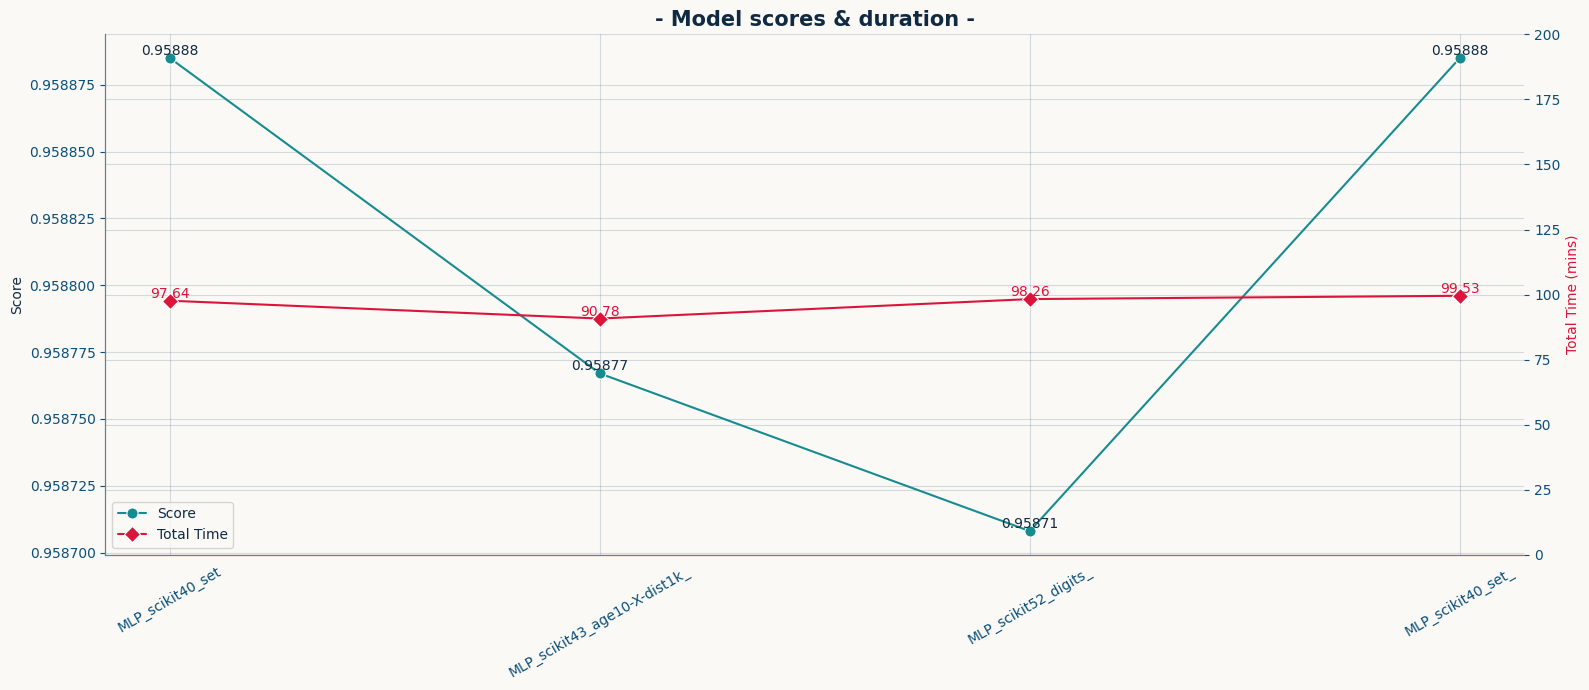

In [201]:
# Extract scores and times
all_scores = {k: v["score"] for k, v in all_predictions.items() if "score" in v}
all_times  = {k: v["total_time"] for k, v in all_predictions.items() if "total_time" in v}

fig, ax1 = plt.subplots(figsize=(16, 7))

# Create twin axis sharing the x-axis
ax2 = ax1.twinx()

# Plot scores on left y-axis (ax1)
sns.lineplot(
    x=range(len(all_scores)),
    y=list(all_scores.values()),
    marker="o", ms=8.0,
    ax=ax1,
    color=TEAL,
    label="Score",
    legend=False,
)

for i, s1 in enumerate(all_scores.values()):
    ax1.text(float(i), s1, f"{s1:.5f}", ha="center", va="bottom", color=INK)

# Plot times on right y-axis (ax2)
sns.lineplot(
    x=range(len(all_times)),
    y=list(all_times.values()),
    marker="D", ms=8.0,
    ax=ax2,
    color=CRIM,
    label="Total Time",
    legend=False,
)
# Axis labels & X-ticks
ax1.set_xticks(range(len(all_scores)))
ax1.set_xticklabels(list(all_scores.keys()), rotation=30)
ax1.set_ylabel("Score", color=INK)

for i, s2 in enumerate(all_times.values()):
    ax2.text(float(i), s2, f"{s2:.2f}", ha="center", va="bottom", color=CRIM)

ax2.set_ylim(0.0, 200.0)
ax2.set_ylabel("Total Time (mins)", color=CRIM)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("- Model scores & duration -", weight="semibold", size=15)
plt.tight_layout()
plt.show()

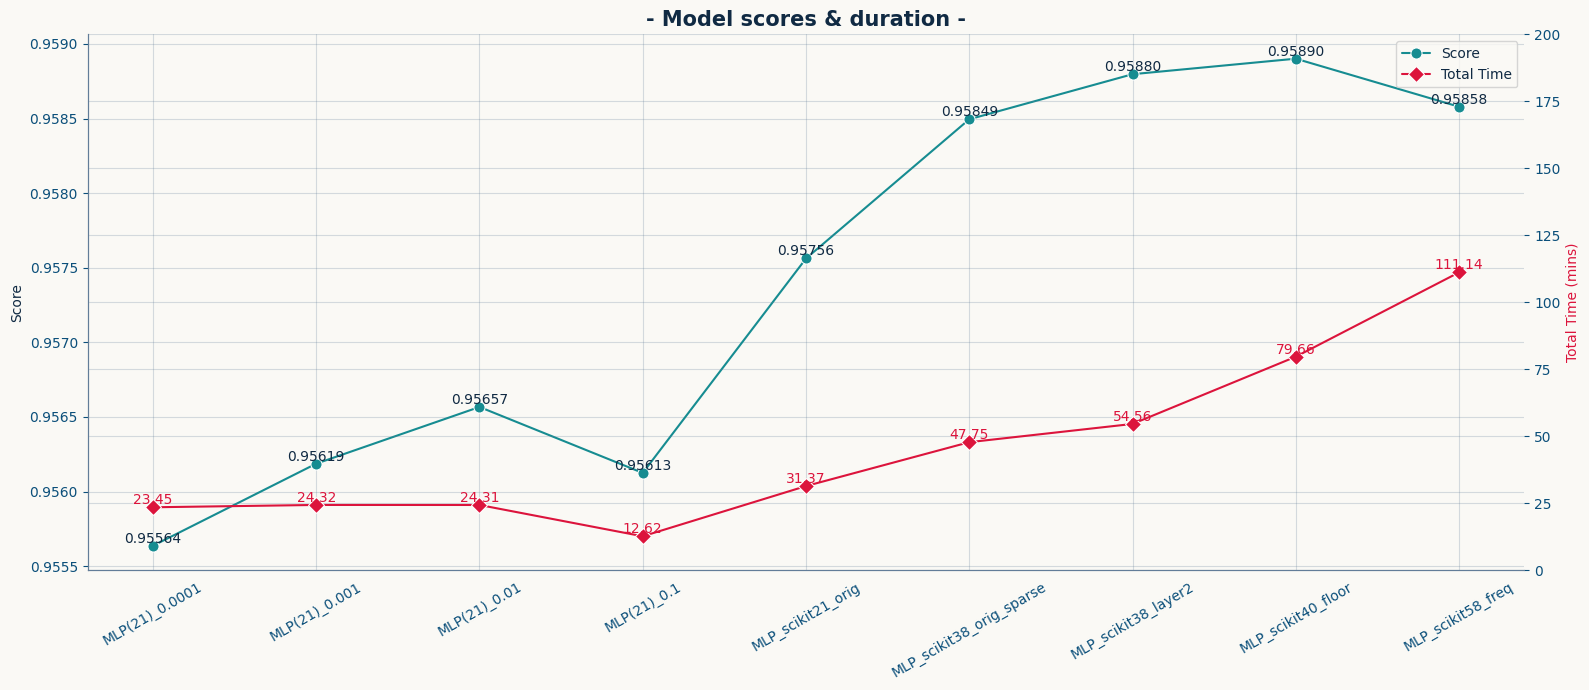

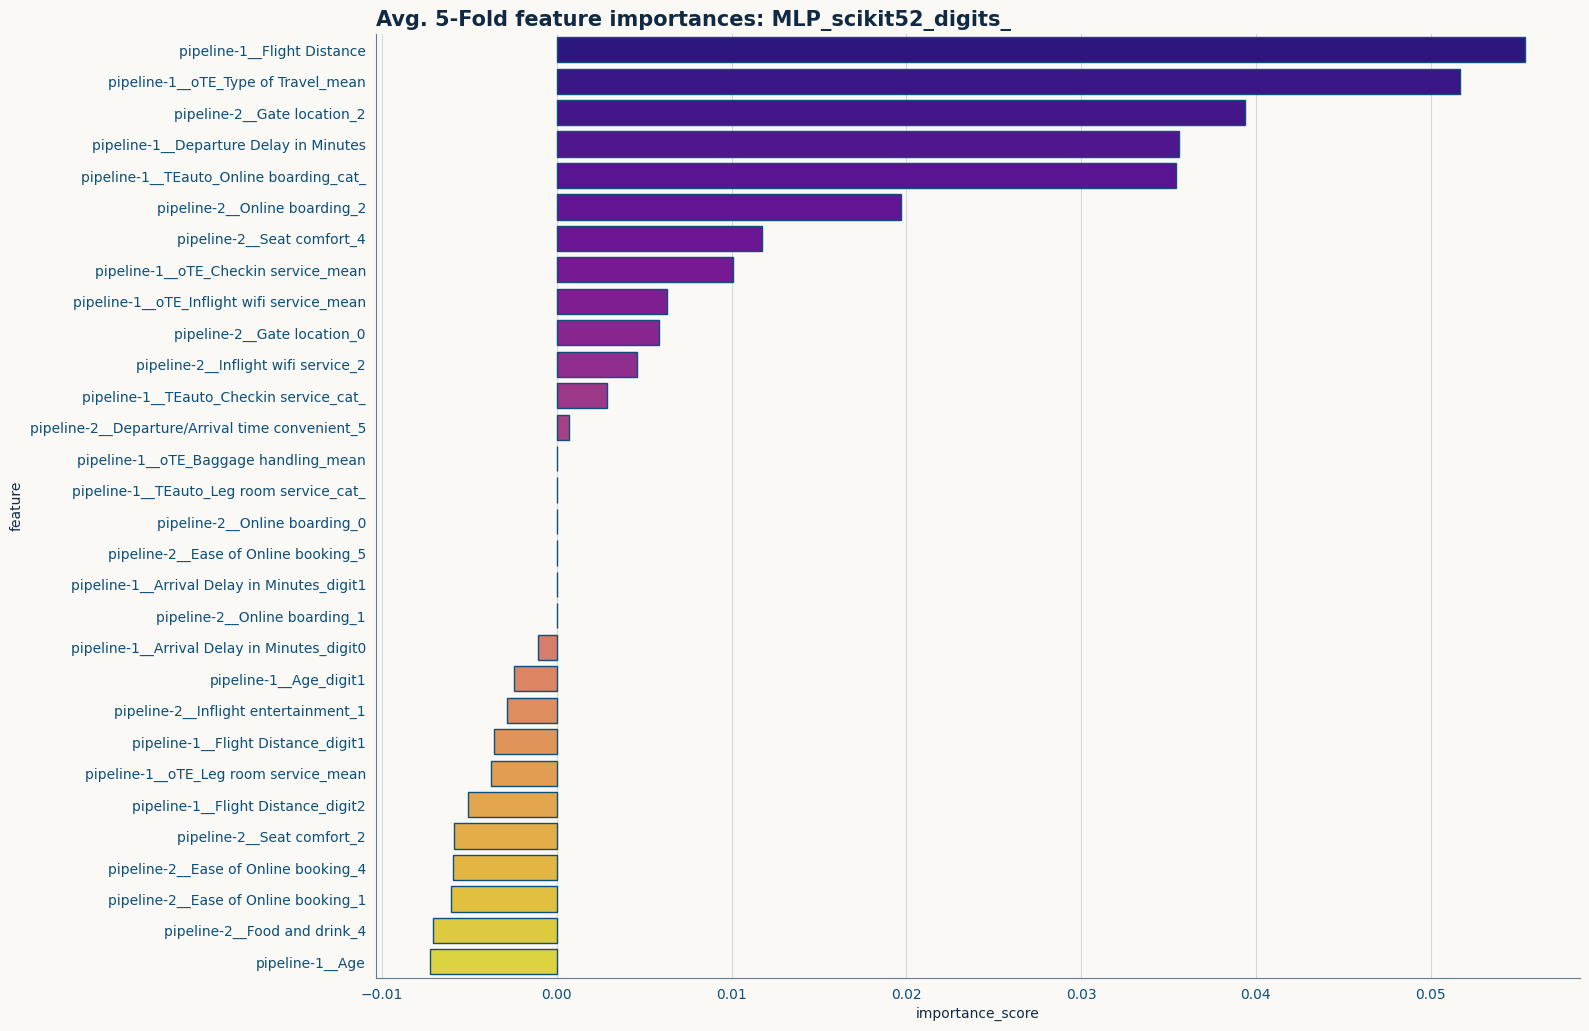

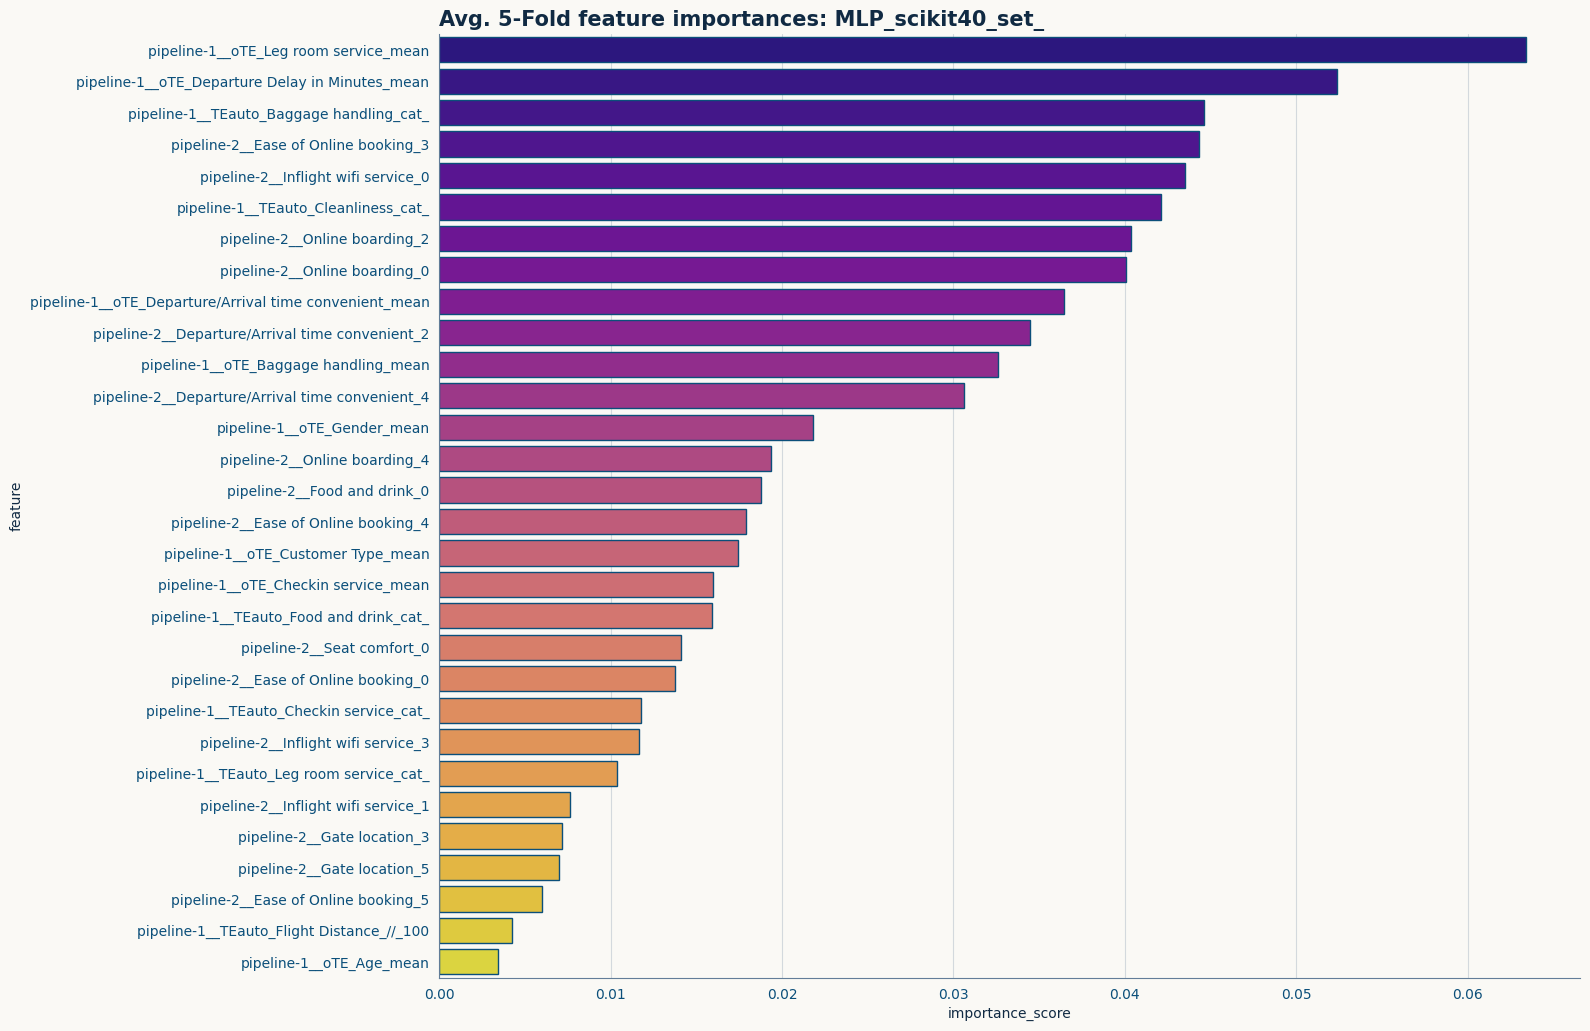

In [204]:
## -- Get feature importances --
all_importances = {k: np.mean(v.get("weights")[1], axis=0) for k, v in all_predictions.items() if "weights" in v}
all_val_data = {k: v.get("weights")[0] for k, v in all_predictions.items() if "weights" in v}

top_n = 30

for i, (m, fi) in enumerate(all_importances.items()):
    fi_df = pd.DataFrame({
        "feature": all_val_data[m][0][:len(fi)],
        # "feature": all_val_data[m][0].columns,
        "importance_score": fi,
    }).sort_values(by="importance_score", ascending=False).reset_index(drop=True)

    plt.figure(figsize=(16, len(all_importances)*10))
    plt.subplot(len(all_importances), 1, i+1)
    sns.barplot(data=fi_df.head(top_n), x="importance_score", y="feature", palette='plasma')
    plt.title(f"Avg. {FOLDS}-Fold feature importances: {m}", size=15, weight="semibold", loc='left')

    plt.tight_layout()
    plt.show()

    print()

In [205]:
try:
    import shap
except:
    !uv pip install shap
    import shap

print(f"Shap version: {shap.__version__}")

Shap version: 0.51.0


In [206]:
"""[
1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1,
0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0,
1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0
]
 """
# val_y

'[\n1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,\n1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,\n0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1,\n0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0,\n1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0\n]\n '

Model pipeline features: 127


PermutationExplainer explainer: 301it [04:07,  1.17it/s]                         


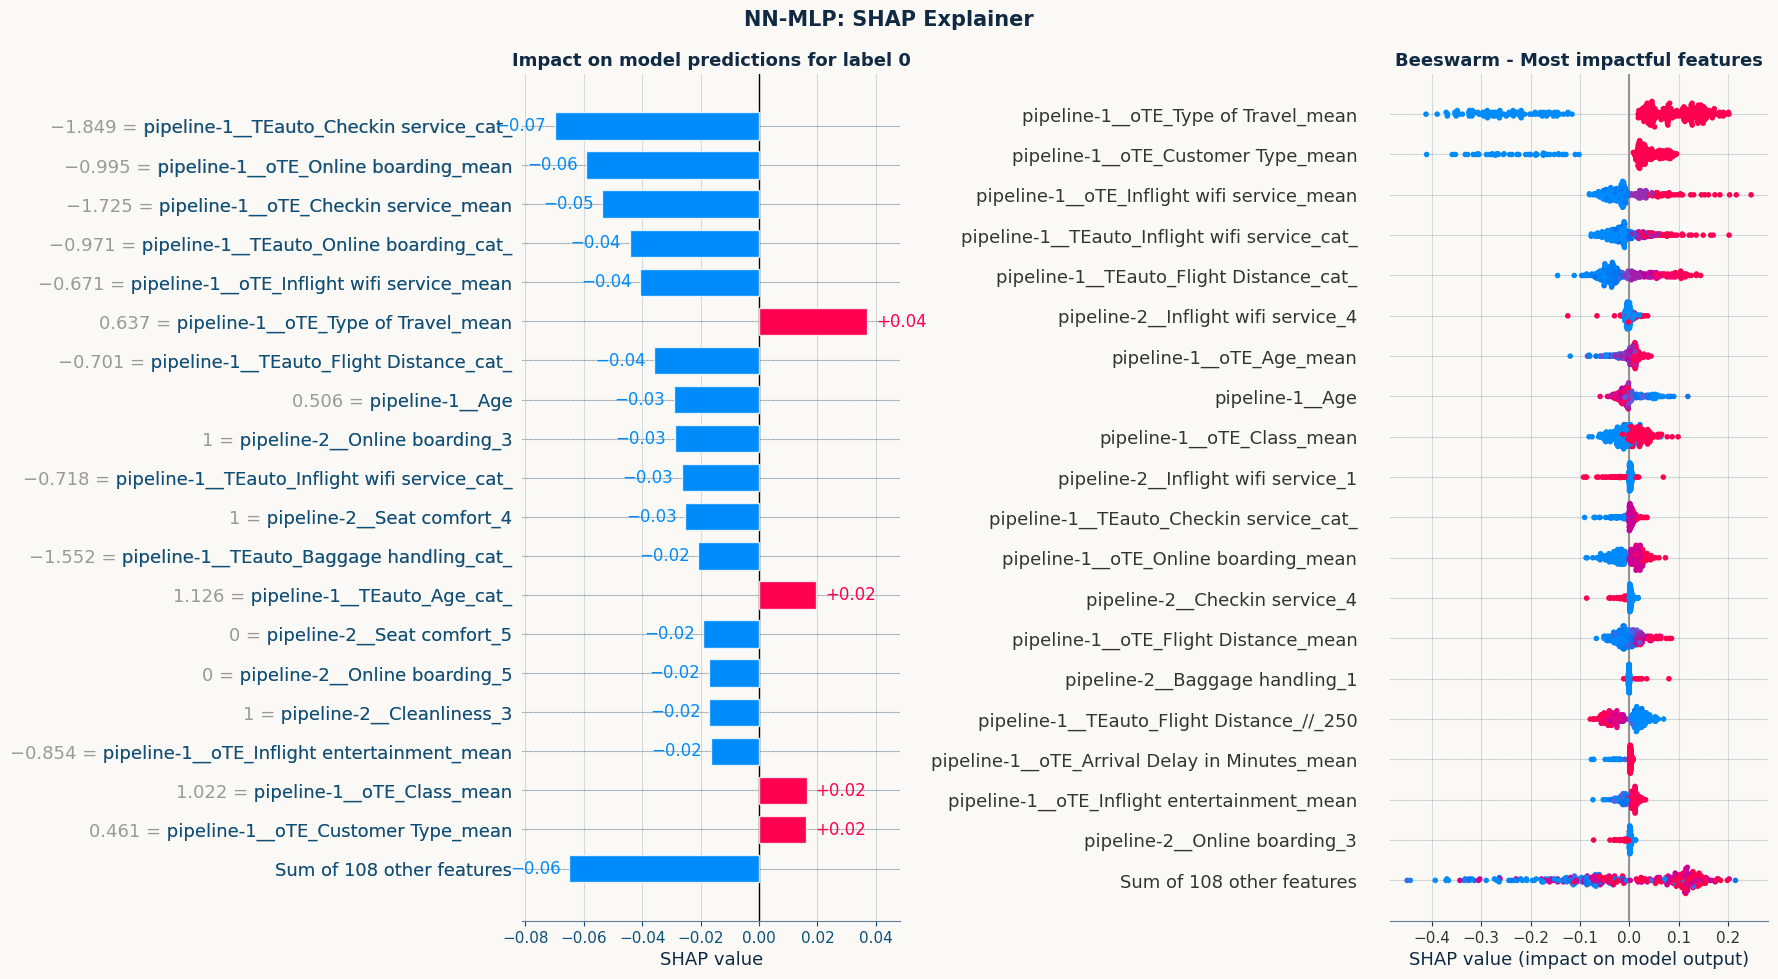

In [207]:
## -- SHAP values: Feature Importances--

models = [
    # ('LOGISTIC', all_predictions[list(all_predictions.keys())[0]]),
    # ('K-NEIGHBORS', all_predictions[list(all_predictions.keys())[1]]),
    ('NN-MLP', all_predictions[list(all_predictions.keys())[-1]]),
]

MAX = 20
_id = 0

for i, (n, m) in enumerate(models):
    feat_names = m["model"].named_steps['columntransformer'].get_feature_names_out()
    print(f"Model pipeline features: {len(feat_names)}")

    x_valid = m["model"][:-1].transform(m["val_data"][0])
    y_label = m["val_data"][1].values

    # Randomly select 100 rows without replacement
    rng = np.random.default_rng(seed=42)
    indices = rng.choice(len(x_valid), size=300, replace=False)

    val_x = x_valid[indices]
    val_y = y_label[indices]

    # model   = m["model"]
    # x_valid = m["val_data"][0]
    # y_label = m["val_data"][1]

    # val_x = x_valid.sample(n=max(150, 2*x_valid.shape[1]+1),random_state=9,ignore_index=True)
    # val_y = y_label.sample(n=max(150, 2*x_valid.shape[1]+1),random_state=9,ignore_index=True)
    
    ## -- Shap Explainer --
    def f(x):
        return m["model"][-1].predict_proba(x)[:, 1]

    explainer   = shap.Explainer(f, val_x, feature_names=feat_names, seed=42)
    explanation = explainer(val_x, max_evals=max(500, 2 * x_valid.shape[1] + 1))

    ## -- Bar plot --
    plt.subplot(121)
    shap.plots.bar(explanation[_id], max_display=MAX, show=False)
    plt.title(f"Impact on model predictions for label {val_y[_id]}")

    ## -- Beeswarm plot --
    plt.subplot(122)
    shap.plots.beeswarm(
        explanation, order=explanation.abs.max(0),
        plot_size=(18, 10), max_display=MAX, color_bar=False, show=False)
    plt.title("Beeswarm - Most impactful features")

    plt.suptitle(f"{n}: SHAP Explainer", size=15, weight="semibold")
    plt.tight_layout(pad=1.5)
    plt.show()

    print()

MLP_scikit40_set_958885 saved!


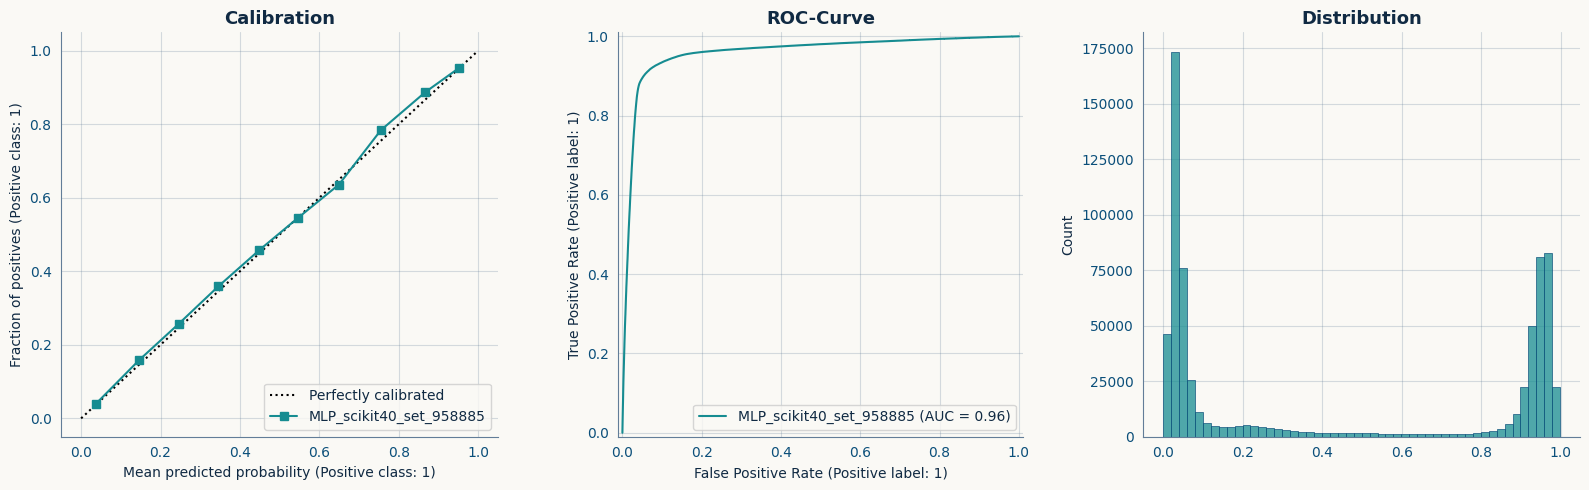


MLP_scikit43_age10-X-dist1k__958767 saved!


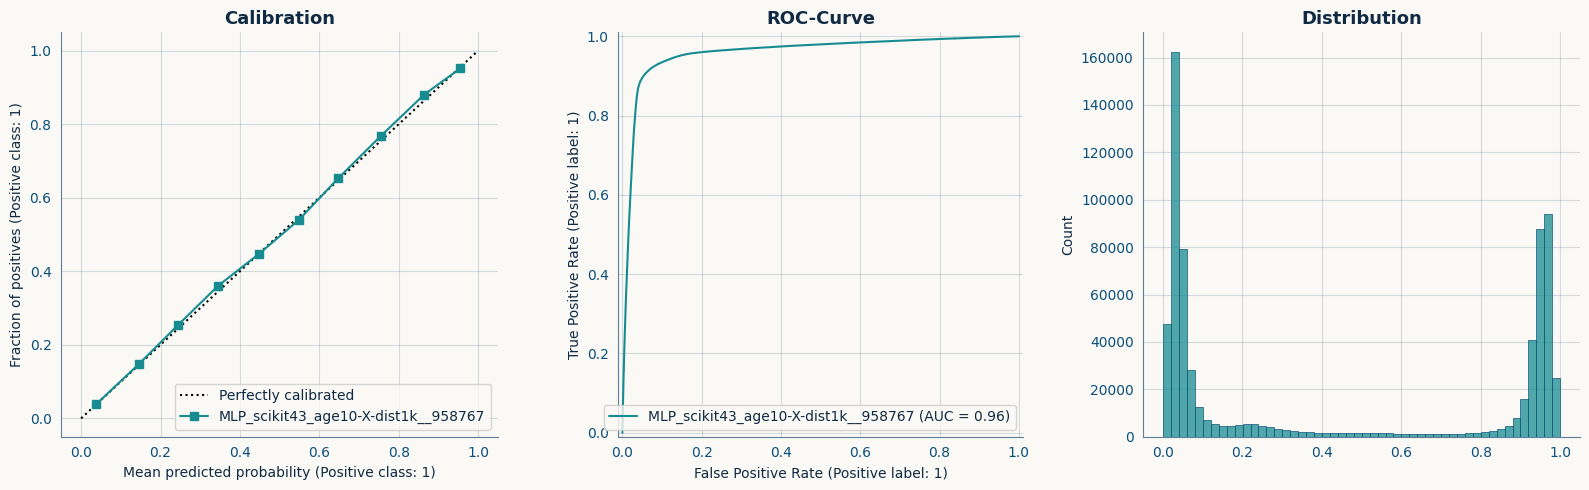


MLP_scikit52_digits__958708 saved!


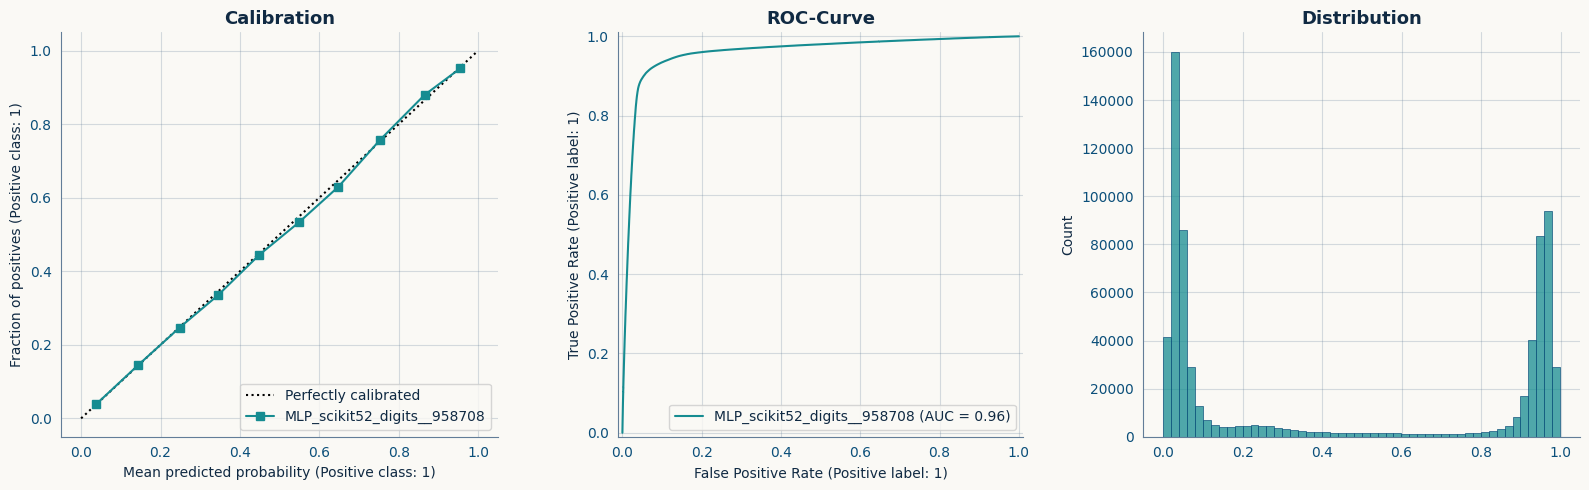


MLP_scikit40_set__958885 saved!


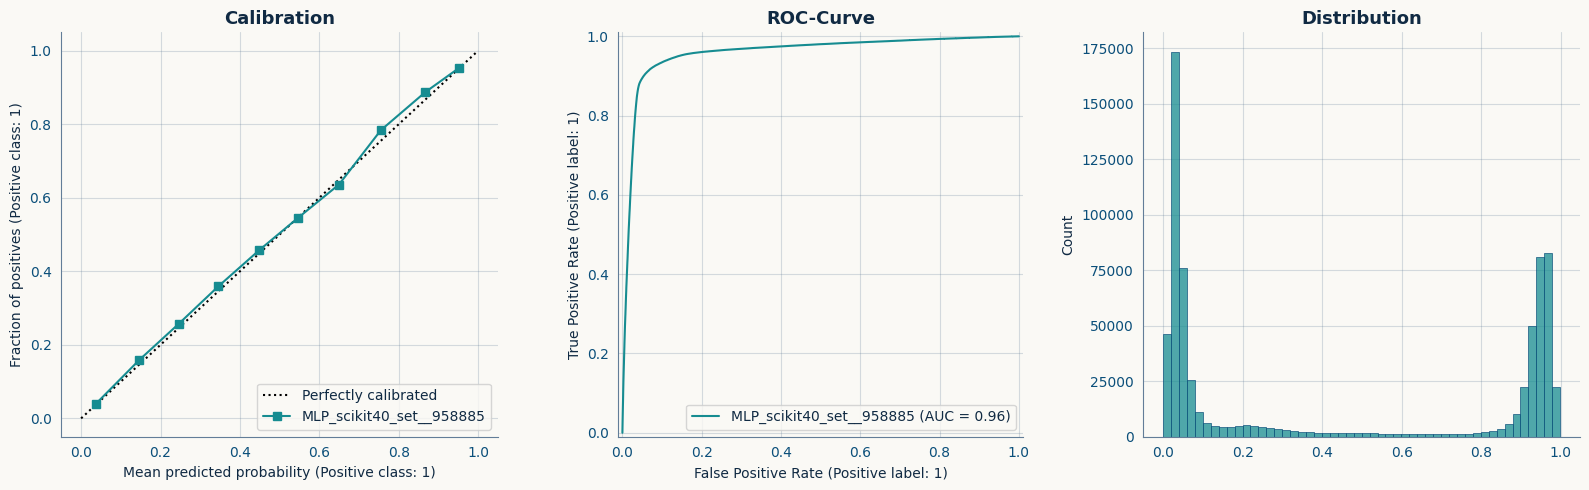

In [208]:
## -- Get oof predictions --
oof_predictions = []

for i, (k, v) in enumerate(all_predictions.items()):
    for key_, data_ in v.items():
        if key_ == "oof_preds":
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"oof_{n}.npy", data_)
            print(f"{n} saved!")

            ## -- Plot distributions --
            _, axs = plt.subplots(1, 3, figsize=(16, 5)) 
            CalibrationDisplay.from_predictions(train_X[TARGET], data_, n_bins=10, name=n, ax=axs[0])
            axs[0].set_title("Calibration")

            RocCurveDisplay.from_predictions(train_X[TARGET], data_, name=n, ax=axs[1])
            axs[1].set_title("ROC-Curve")

            sns.histplot(data_, ax=axs[2], bins=50)
            axs[2].set_title("Distribution")
            
            plt.tight_layout()
            plt.show()

            print()

In [209]:
## -- Save test predictions/submissions --
model_results = {}

for i, (k, v) in enumerate(all_predictions.items()):
    for j, (x, y) in enumerate(v.items()):
        if x == "test_preds":
            ## -- Base submission file --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"test_{n}.npy", y)

            submit[TARGET] = y
            submit.to_csv(f"submit_{n}.csv", index=False)
            print(f"{n:>20} saved! {y.shape}")

            model_results[n[:-6]] = y

print()
model_results = pd.DataFrame(model_results)
model_results

MLP_scikit40_set_958885 saved! (299844,)
MLP_scikit43_age10-X-dist1k__958767 saved! (299844,)
MLP_scikit52_digits__958708 saved! (299844,)
MLP_scikit40_set__958885 saved! (299844,)



,MLP_scikit40_set_,MLP_scikit43_age10-X-dist1k__,MLP_scikit52_digits__,MLP_scikit40_set__
0,0.210905,0.209135,0.232162,0.210905
1,0.880579,0.891979,0.881768,0.880579
2,0.936009,0.930890,0.943434,0.936009
3,0.086712,0.081461,0.074028,0.086712
4,0.061013,0.066733,0.064882,0.061013
...,...,...,...,...
299839,0.069001,0.062647,0.049860,0.069001
299840,0.035861,0.044130,0.047693,0.035861
299841,0.210017,0.225260,0.233321,0.210017
299842,0.022212,0.026504,0.023768,0.022212


In [ ]:
# load_sample = np.load("/kaggle/working/test_knn_87175_.npy")
# load_sample[:5]

In [ ]:
# !rm -r /kaggle/working/

# HILLCLIMB

In [ ]:
# try:
#     from hillclimbers import climb_hill, partial
# except:
#     %pip install -q -U hillclimbers
#     from hillclimbers import climb_hill, partial

# ## -- Load data --
# oof_df = pd.DataFrame()
# test_df = pd.DataFrame()

# print('Loading data: ', end='')
# for (root, dirs, files) in os.walk('/kaggle/working'):
#     for i, file in enumerate(sorted(files), 1):
#         if i%5 == 0: print(f'{i}%.. ', end='')
#         if file.endswith('.npy') and 'oof' in file:
#             oof_df = pd.concat([oof_df, pd.Series(np.load(os.path.join(root, file)),
#                                 name=file[4:-4])], axis=1)
#         elif file.endswith('.npy') and 'test' in file:
#             test_df = pd.concat([test_df, pd.Series(np.load(os.path.join(root, file)),
#                                 name=file[5:-4])], axis=1)

# print(CFG.YELLOW)
# print(f"OOF  loaded : {oof_df.shape}")
# print(f"TEST loaded : {test_df.shape}")

# display(oof_df.head())
# display(test_df.head())

In [ ]:
# %%time

# trn = pd.read_csv(PATH+'train.csv').drop(columns=['id'])

# pred_hc, oof_hc = climb_hill(
#                                train = trn,
#                               target = TARGET,
#                          oof_pred_df = oof_df,
#                         test_pred_df = test_df,
#                            objective = 'maximize',
#                          eval_metric = partial(roc_auc_score),
#                     # negative_weights = True,
#                     return_oof_preds = True,
#                            precision = 0.01,
#                            plot_hill = True,
#                            plot_hist = True,
# )

In [ ]:
# hc_auc = str(round(roc_auc_score(train[TARGET], oof_hc), 5)).split('.')[1]
# print(f"Hillclimb score: {hc_auc}")

# n = 'log-knn-mlp'
# np.save(f"oof_{n}_hillclimb_{hc_auc}.npy", oof_hc)
# np.save(f"test_{n}_hillclimb_{hc_auc}.npy", pred_hc)

# submit[TARGET] = pred_hc
# submit.to_csv(f"submit_{n}_hillclimb_{hc_auc}.csv", index=False)
# print(f"\n✅ Saved hillclimb ensemble!!!")

# submit.head(10)